In [2]:
import torch
import copy
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import ep07_plots as viz

print(torch.__version__)


2.13.0+cu130


In [ ]:
train_set = datasets.FashionMNIST("data", train = True, download = True)
test_set = datasets.FashionMNIST("data", train=False, download = True)

print(len(train_set), "photos for learning")


60000 photos for learning
10000 photos for the board exam
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
print(len(test_set), "photos for the board exam")


print(train_set.classes)

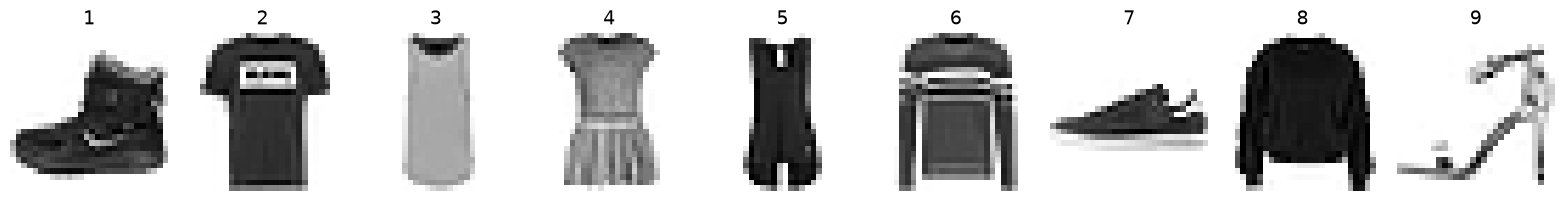

In [6]:
viz.show_photos(train_set.data[:9])

tensor([9, 0, 0, 3, 0, 2, 7, 2, 5])


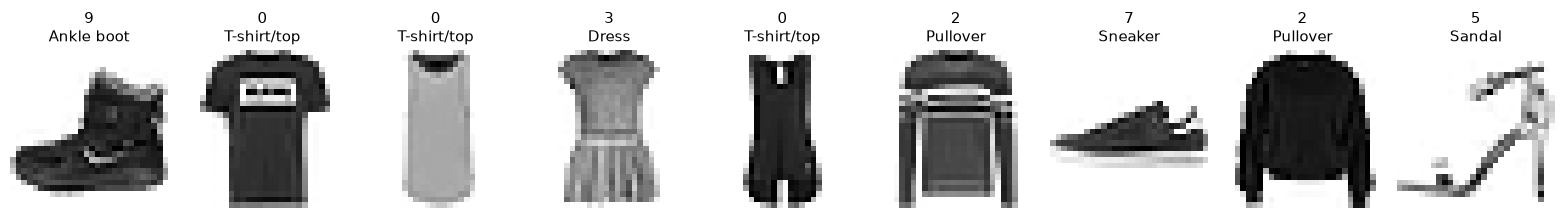

In [7]:
labels = train_set.targets[:9]
print(labels)
viz.show_photos(train_set.data[:9], labels, train_set.classes)

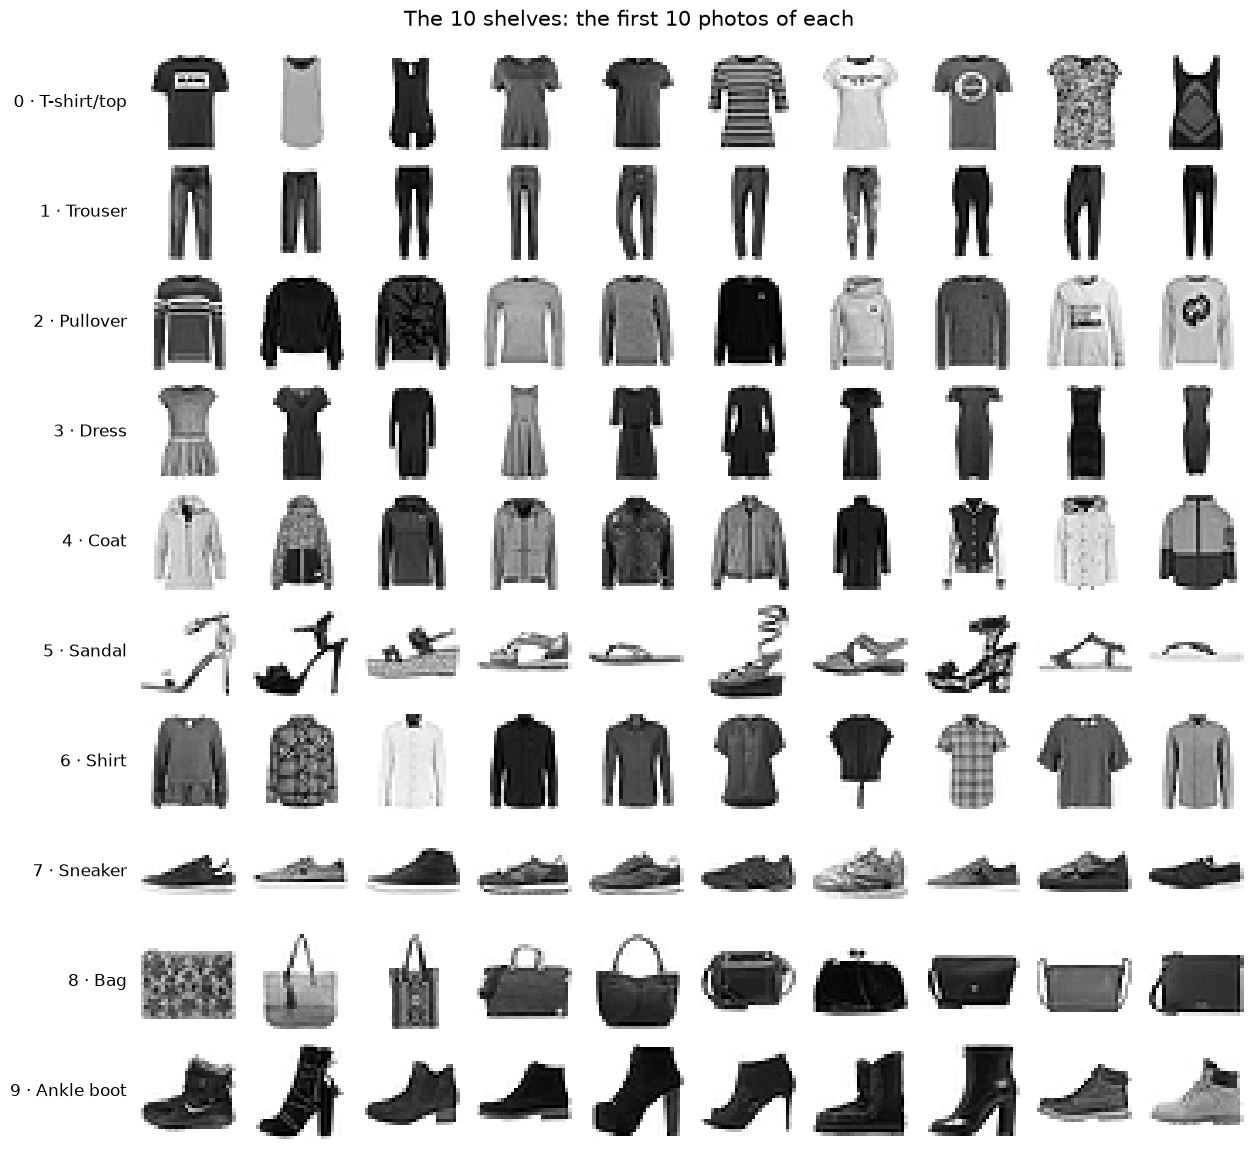

In [8]:
viz.show_shelves(train_set.data, train_set.targets, train_set.classes)

torch.Size([28, 28]) torch.uint8
smallest:  0 | biggest:  255


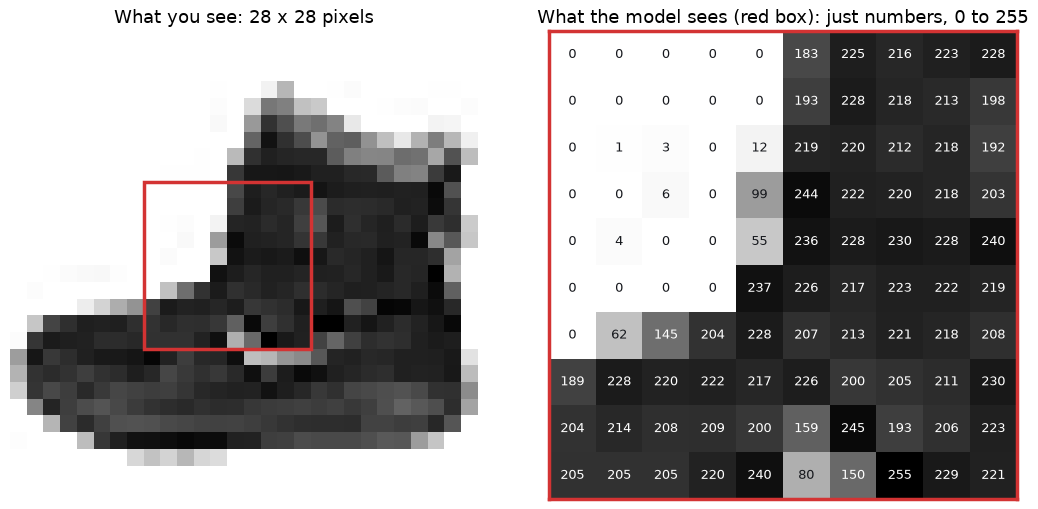

In [9]:
photo = train_set.data[0]
print(photo.shape, photo.dtype)
print("smallest: ", photo.min().item(), "| biggest: ", photo.max().item())
viz.show_numbers(photo)

In [10]:
# 28 rows and 28 columns
28 * 28

784

In [11]:
X = train_set.data.float() / 255
y = train_set.targets
X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:], y[50000:]
X_test = test_set.data.float() / 255
y_test = test_set.targets
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([50000, 28, 28]) torch.Size([10000, 28, 28]) torch.Size([10000, 28, 28])


In [13]:
y_train.unique()

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

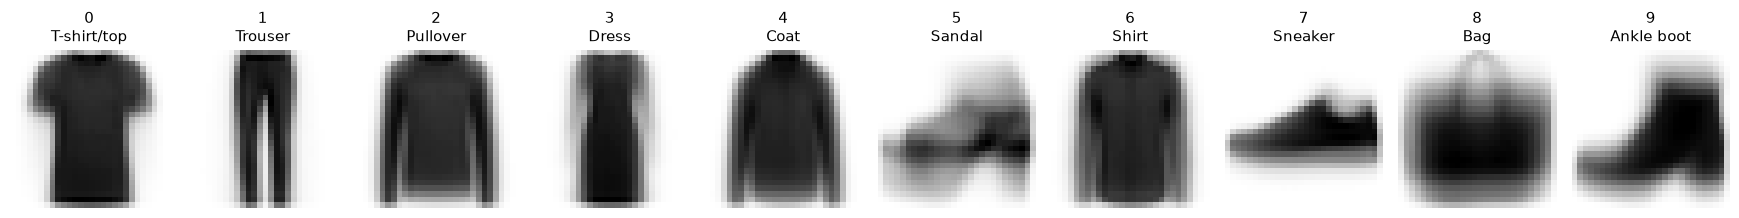

In [14]:
ghosts = []
for k in range(10):
    ghosts.append(X_train[y_train == k].mean(dim = 0))

ghosts = torch.stack(ghosts)
viz.show_photos(ghosts, range(10), train_set.classes)

In [15]:
# The laziest assistance
distance = torch.cdist(X_val.flatten(1),ghosts.flatten(1))
lazy = distance.argmin(dim = 1)
right = (lazy == y_val).float().mean().item()
print("laziest assistant, mock test: ", round(right, 3))

laziest assistant, mock test:  0.69


## Flatten the photo

torch.Size([1, 28, 28]) -> torch.Size([1, 784])


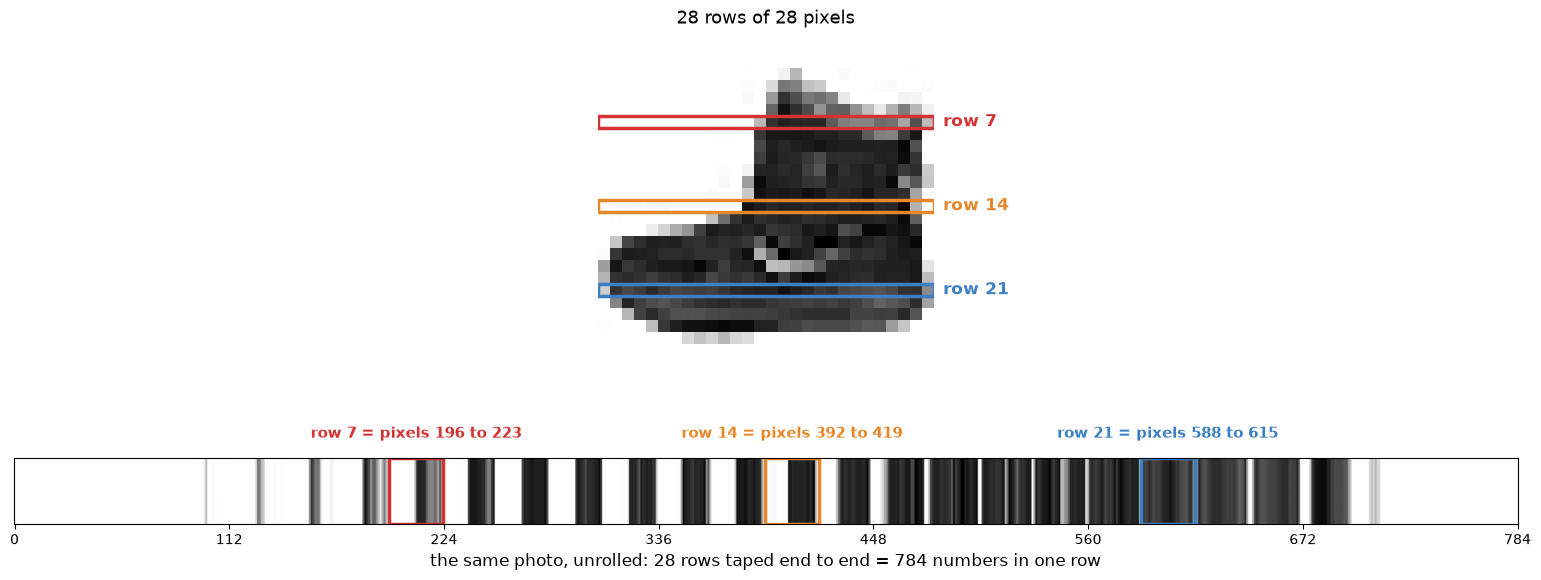

In [16]:
flatten = nn.Flatten()
row = flatten(X_train[:1])
print(X_train[:1].shape, "->", row.shape)
viz.show_unroll(X_train[0])

## Think of every photo as a barcode after we flatten it 

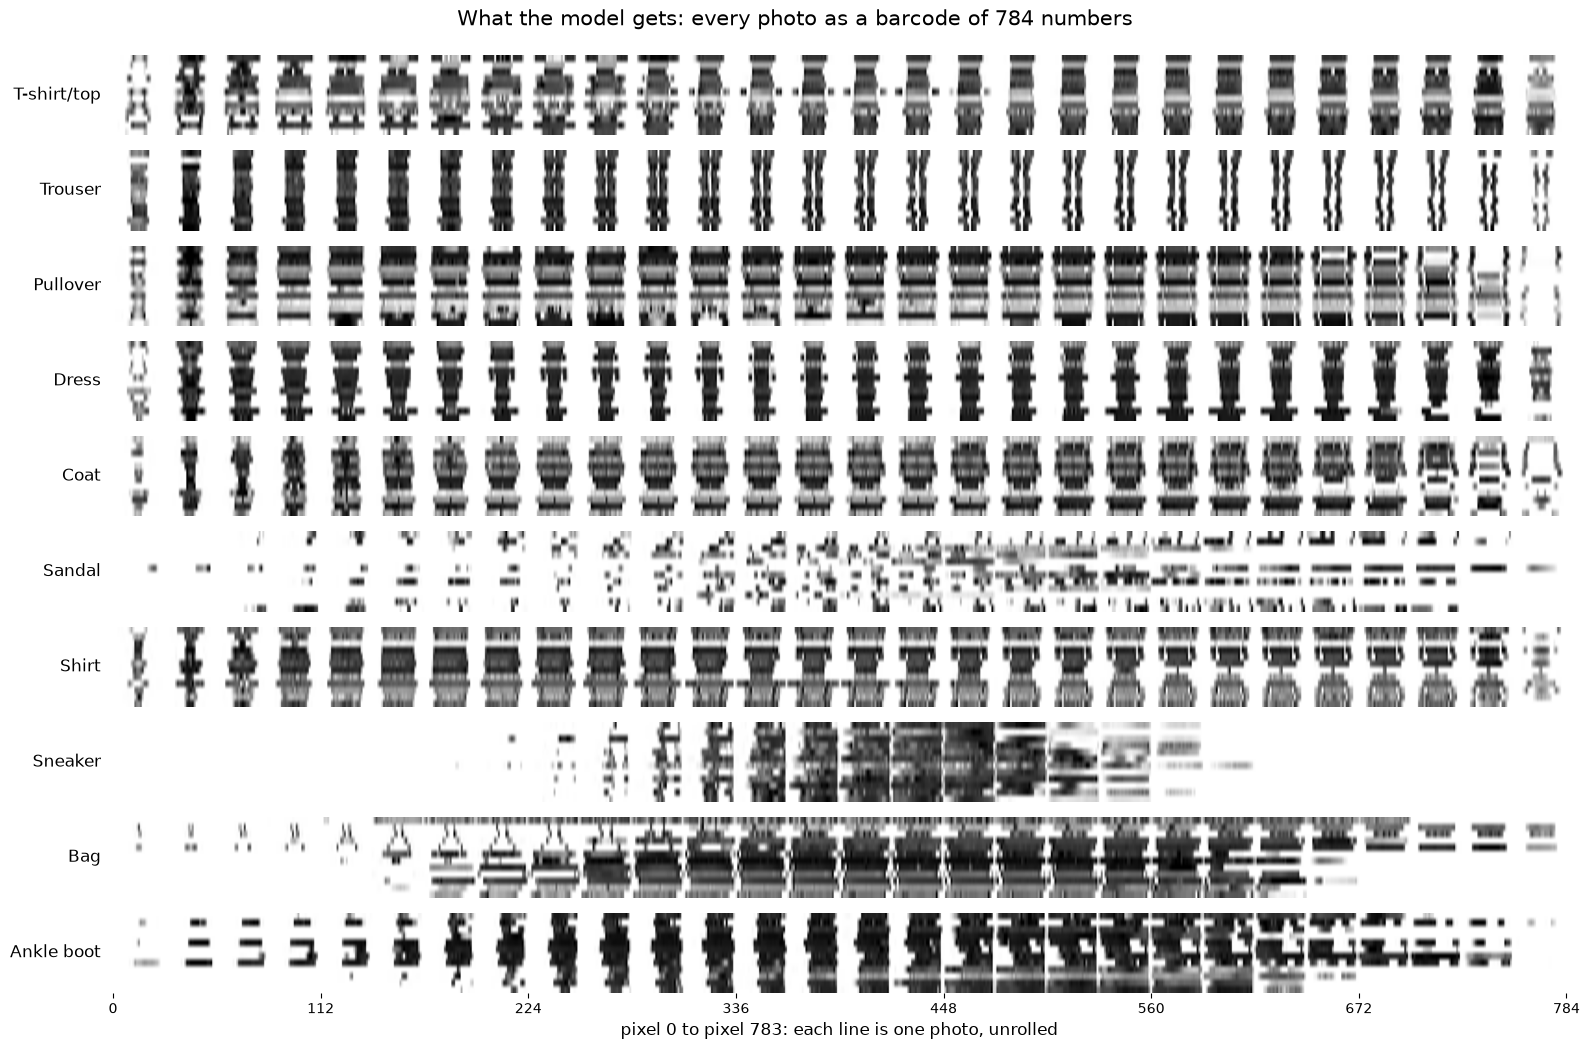

In [17]:
viz.show_barcodes(X_train, y_train, train_set.classes)

## The shop model

knobs:  109386


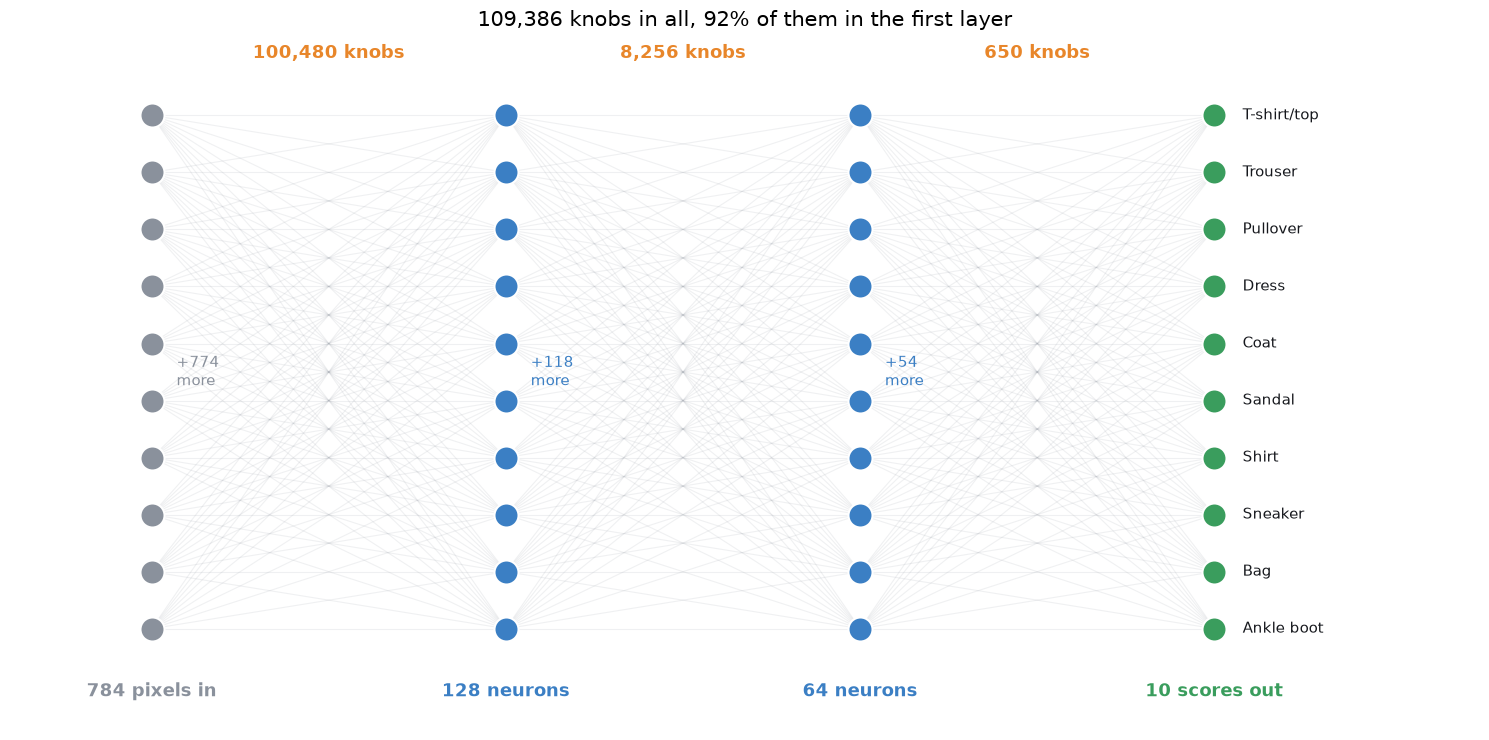

In [21]:
def new_shop_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, 10)
    )

knobs = sum(p.numel() for p in new_shop_model().parameters())
print("knobs: ", knobs)
viz.show_network(new_shop_model(), train_set.classes)

In [22]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    losses = []
    for xb, yb in loader:
        predictions = model(xb)
        loss = loss_fn(predictions, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return loss

before studying, mock test:  0.064


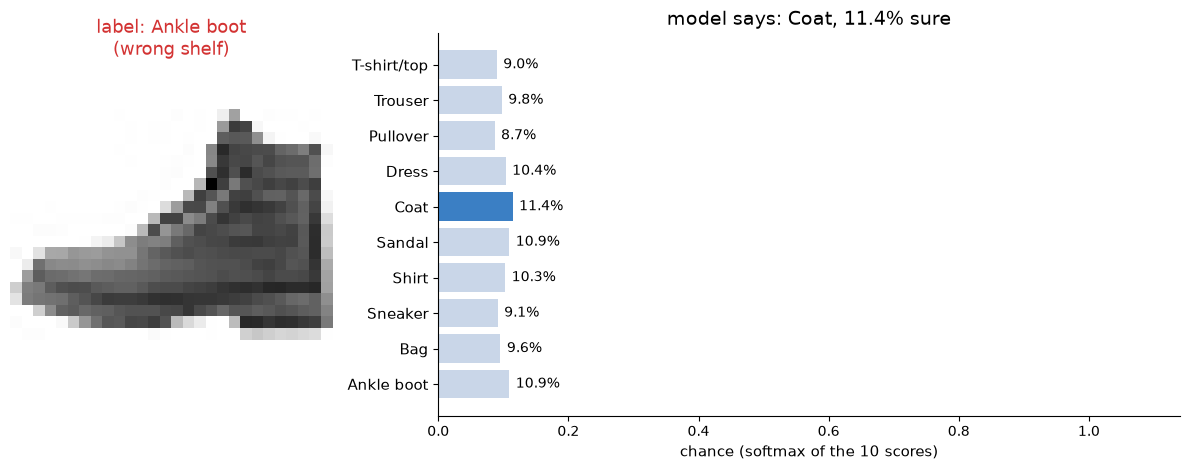

In [23]:
loss_fn = nn.CrossEntropyLoss()

def accuracy(model, X, y):
    with torch.no_grad():
        picked = model(X).argmax(dim = 1)      # Select the biggest score
    return round((picked == y).float().mean().item(), 3)

torch.manual_seed(42)
model = new_shop_model()
print("before studying, mock test: ", accuracy(model, X_val, y_val))
viz.show_chances(model, X_val[0], train_set.classes, y_val[0])

In [28]:
torch.manual_seed(42)
model = new_shop_model()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
loader = DataLoader(TensorDataset(X_train, y_train), 
                    batch_size=64, shuffle = True)
best_acc, patience, bad_epoch = 0, 5, 0

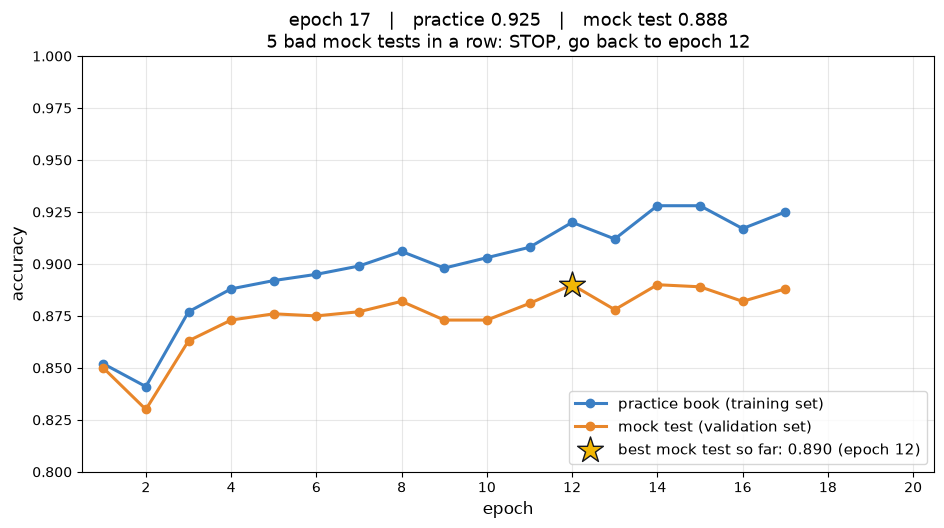

In [29]:
for epoch in range(1, 41):
    train_one_epoch(model, loader, loss_fn, optimizer)
    practice = accuracy(model, X_train, y_train)
    mock = accuracy(model, X_val, y_val)
    viz.live_chart(epoch, practice, mock)
    if mock > best_acc:
        best_acc, best_epoch, bad_epoch = mock, epoch, 0
        best_state = copy.deepcopy(model.state_dict())   # Snapshot of the model weights and biases
    else:
        bad_epoch += 1
    if bad_epoch == patience:                            # Patience = 5 even after 5 epochs accuracy does not inrease break
        break

## Board exam of the model

In [30]:
model.load_state_dict(best_state)     # loading the model
print("best mock test: ", best_epoch)
print("practice book: ", accuracy(model, X_train, y_train))
print("mock test: ", accuracy(model, X_val, y_val))
print("board exam: ", accuracy(model, X_test, y_test))

best mock test:  12
practice book:  0.92
mock test:  0.89
board exam:  0.881


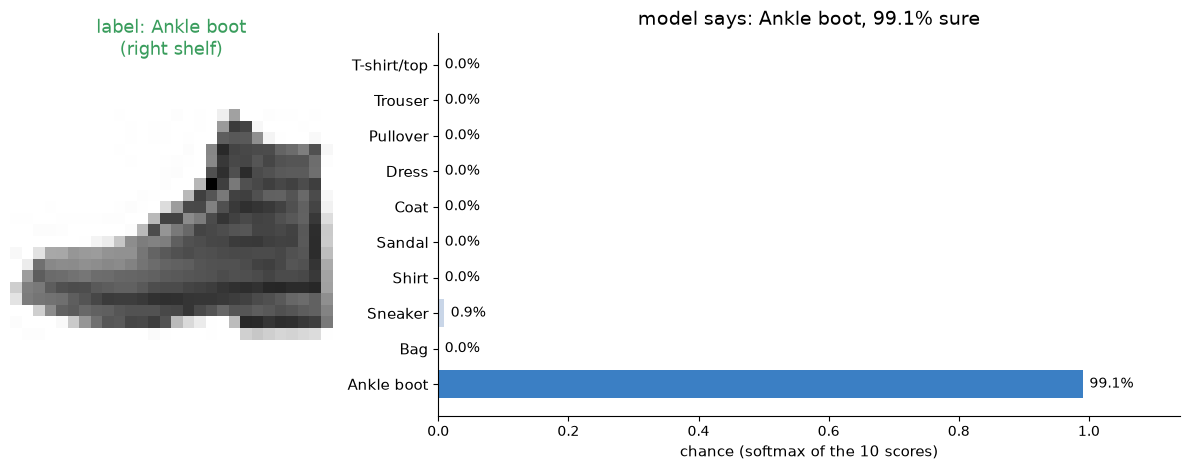

In [31]:
viz.show_chances(model, X_val[0], train_set.classes, y_val[0])

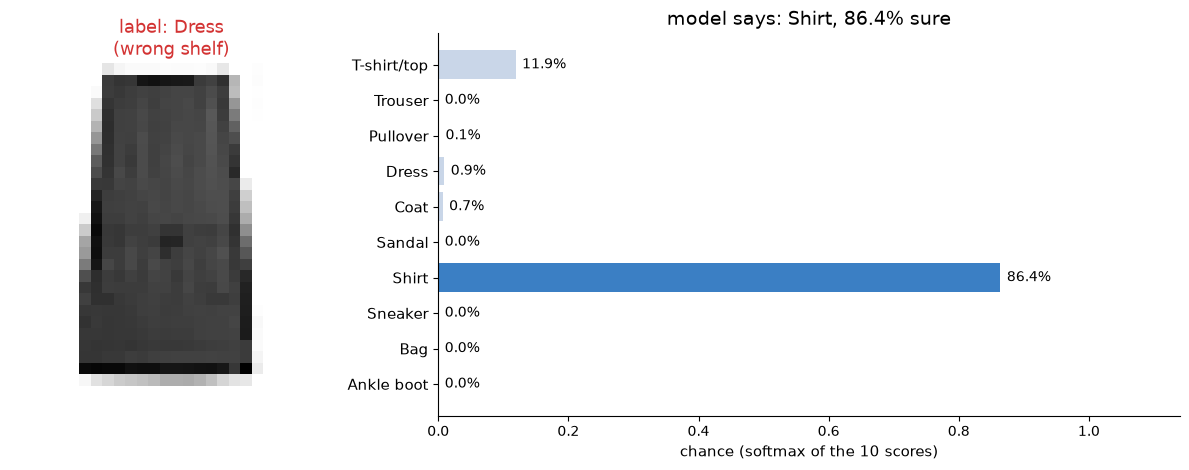

In [34]:
i = 42
viz.show_chances(model, X_test[i], train_set.classes, y_test[i])


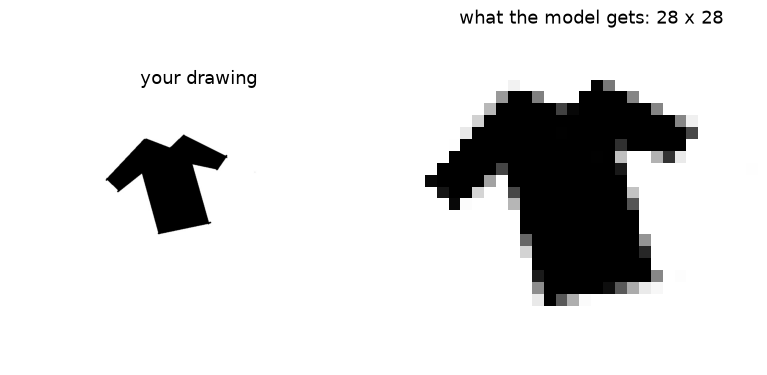

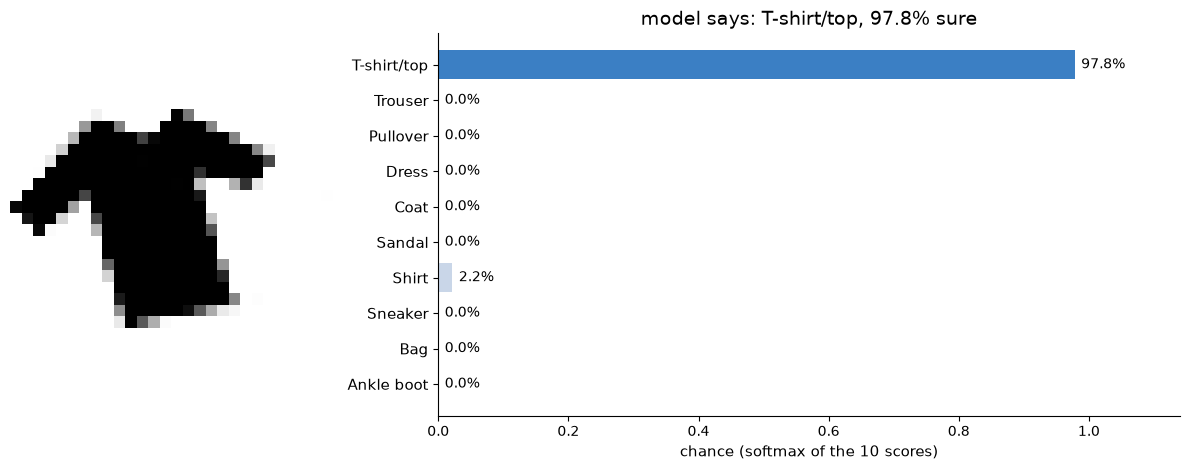

In [35]:
mine = viz.load_drawing("t-shirt.jpg")
viz.show_chances(model, mine, train_set.classes)

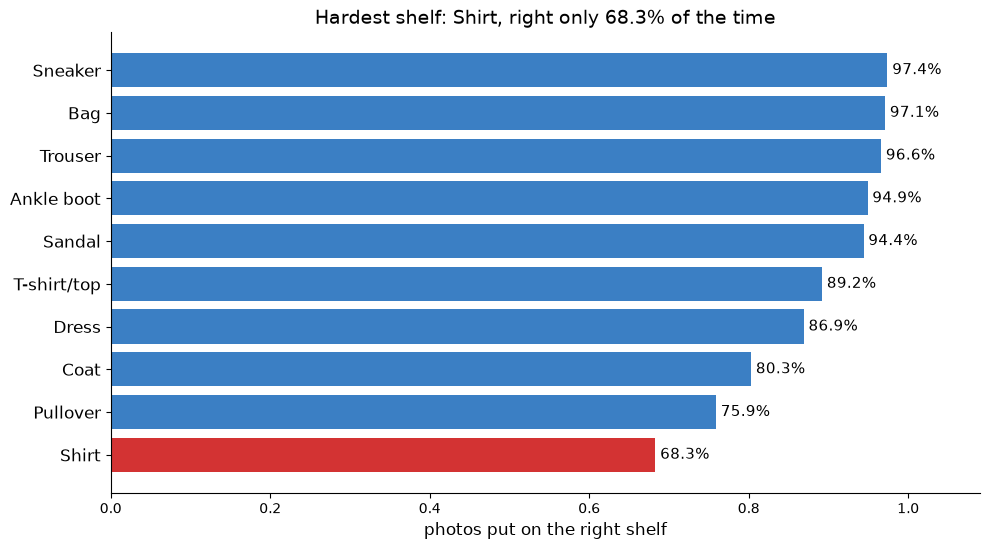

In [36]:
with torch.no_grad():
    picked = model(X_test).argmax(dim = 1)
scores = []
for k in range(10):
    scores.append((picked[y_test == k] == k).float().mean().item())
viz.show_shelf_scores(scores, train_set.classes)

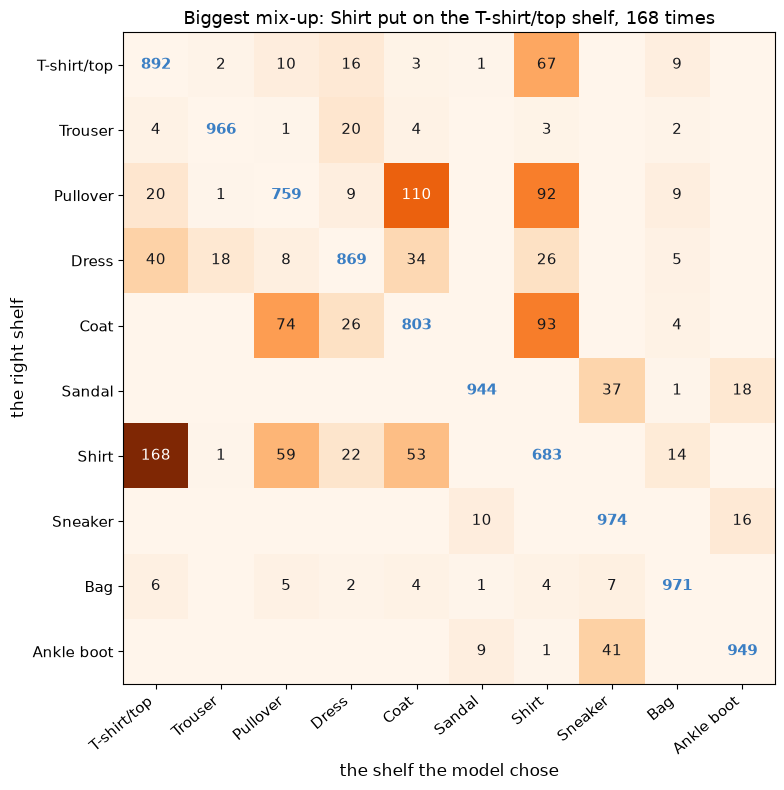

In [37]:
viz.show_confusion(model, X_test, y_test, train_set.classes)

## Model is wrong but very confident

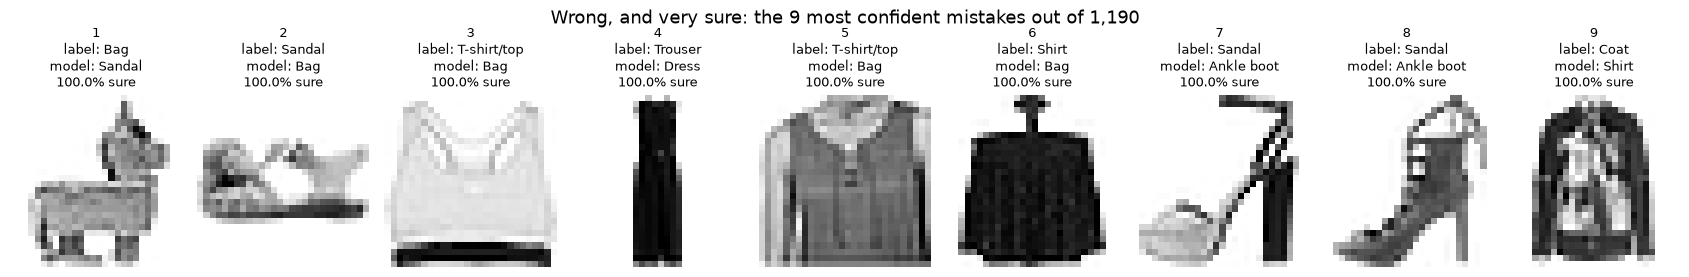

In [38]:
viz.show_mistakes(model, X_test, y_test, train_set.classes)

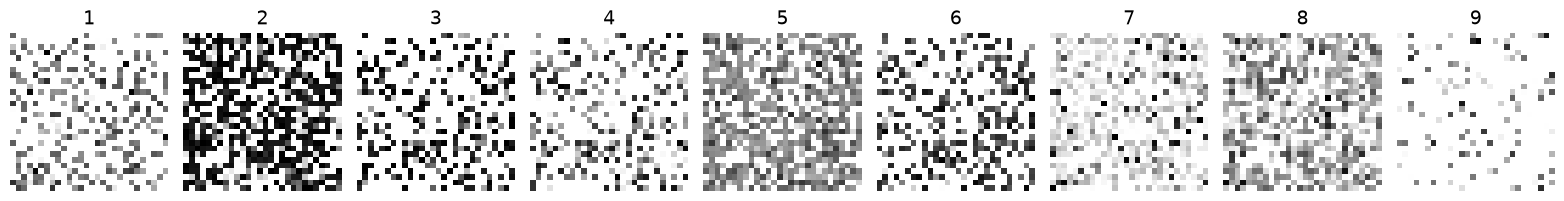

In [39]:
torch.manual_seed(42)
order = torch.randperm(784)                          # Shuffle

def scramble(X):
    return X.reshape(-1, 784)[:, order].reshape(-1, 28,28)

X_train_s, X_test_s = scramble(X_train), scramble(X_test)
viz.show_photos(X_test_s[:9])

In [41]:
torch.manual_seed(42)
model_s = new_shop_model()
optimizer = torch.optim.Adam(model_s.parameters(), lr = 0.001)
loader = DataLoader(TensorDataset(X_train_s, y_train),
                    batch_size=64, shuffle = True)

for erpoch in range(1, best_epoch + 1):
    train_one_epoch(model_s, loader, loss_fn, optimizer)
print("Normal photos: ", accuracy(model, X_test, y_test))
print("Scrambled  photos: ", accuracy(model_s, X_test_s, y_test))

Normal photos:  0.881
Scrambled  photos:  0.878


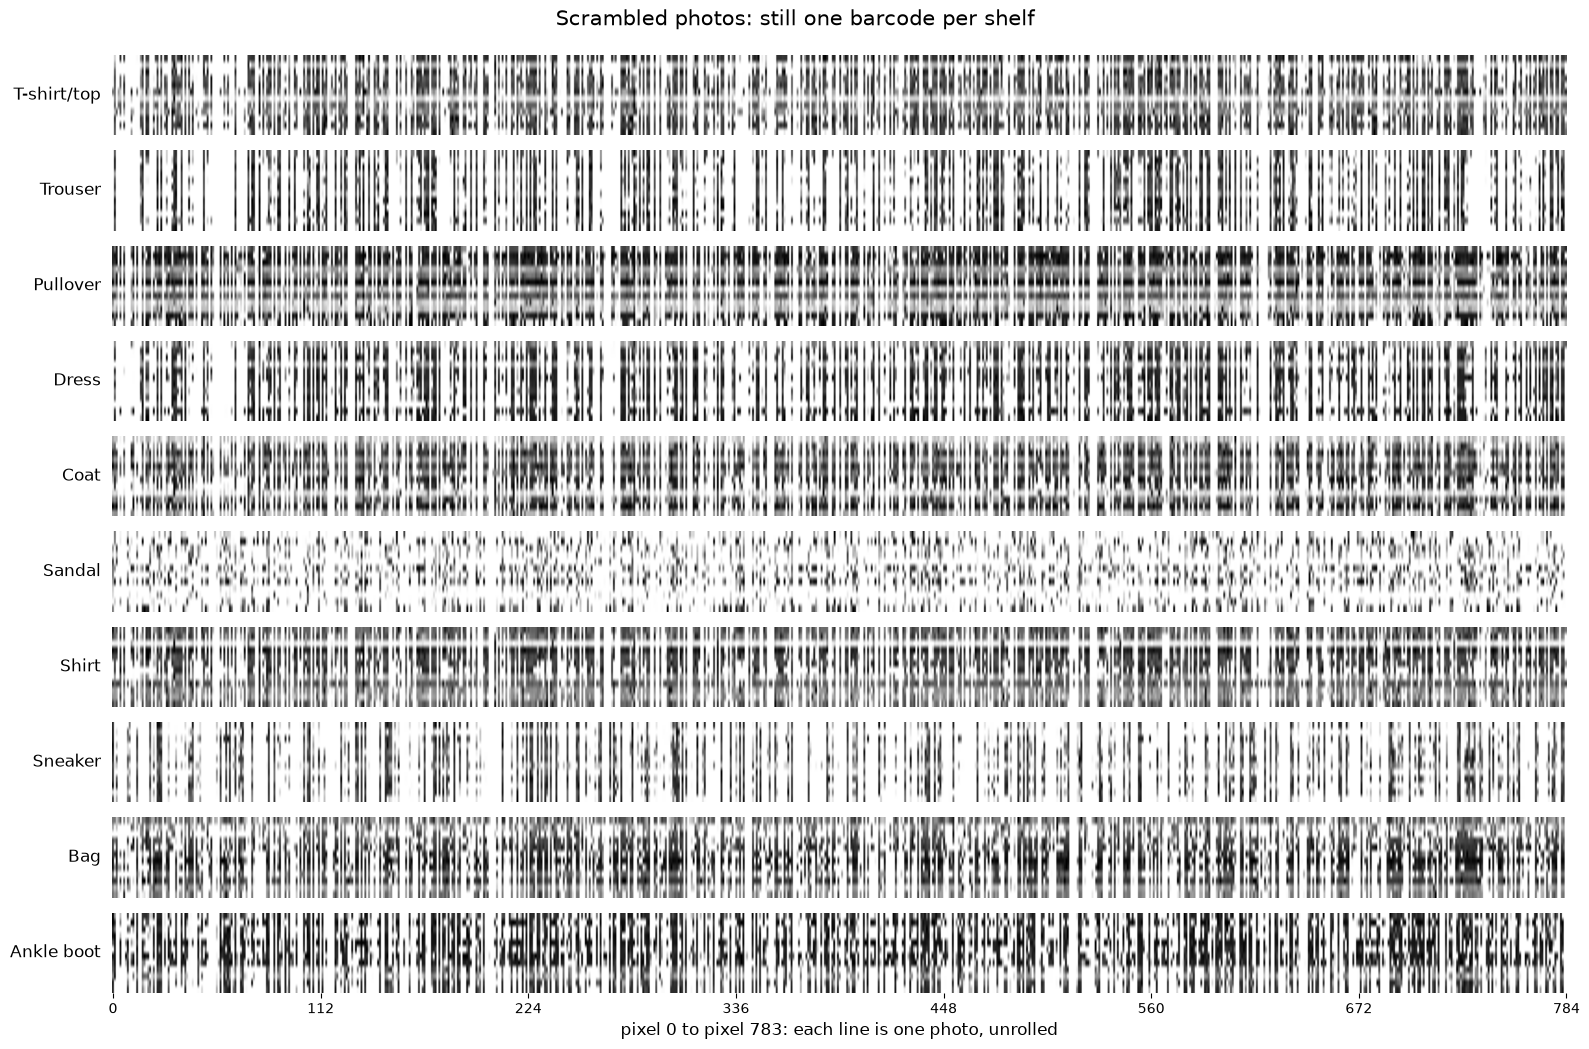

In [42]:
viz.show_barcodes(X_train_s, y_train, train_set.classes,
                  title = 'Scrambled photos: still one barcode per shelf')

In [43]:
torch.save(model.state_dict(), "shop_model.pt")      # Brain file

torch.manual_seed(42)
new_assistant = new_shop_model()                     # empty brain
print("before loading: ", accuracy(new_assistant, X_test, y_test))
new_assistant.load_state_dict(torch.load("shop_model.pt"))
print("after loading: ", accuracy(new_assistant, X_test, y_test))


before loading:  0.061
after loading:  0.881


## Open the brain of the model

torch.Size([128, 784])


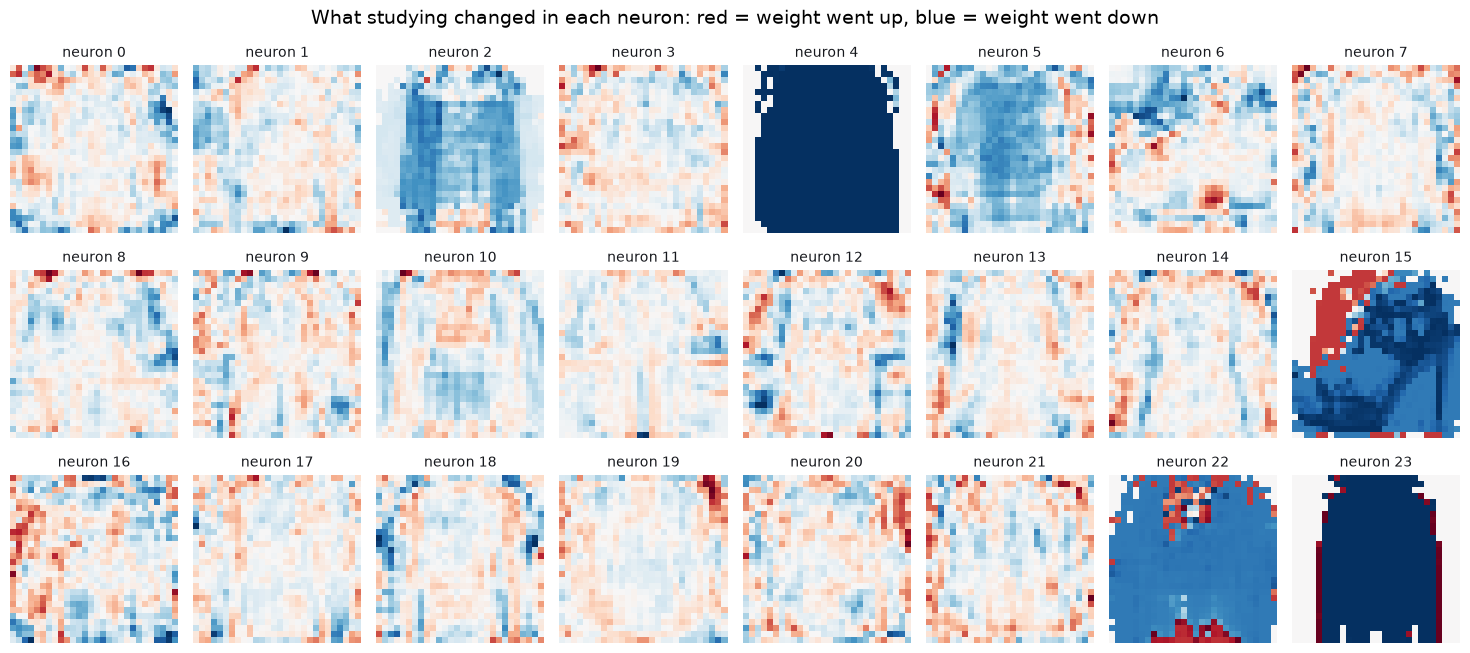

In [49]:
torch.manual_seed(42)
start = new_shop_model()                              # brain without studying

with torch.no_grad():
    learned = model[1].weight - start[1].weight      # what studying changed

print(learned.shape)
viz.show_neurons(learned)

## Dead neurons

dead neurons:  16 of 128


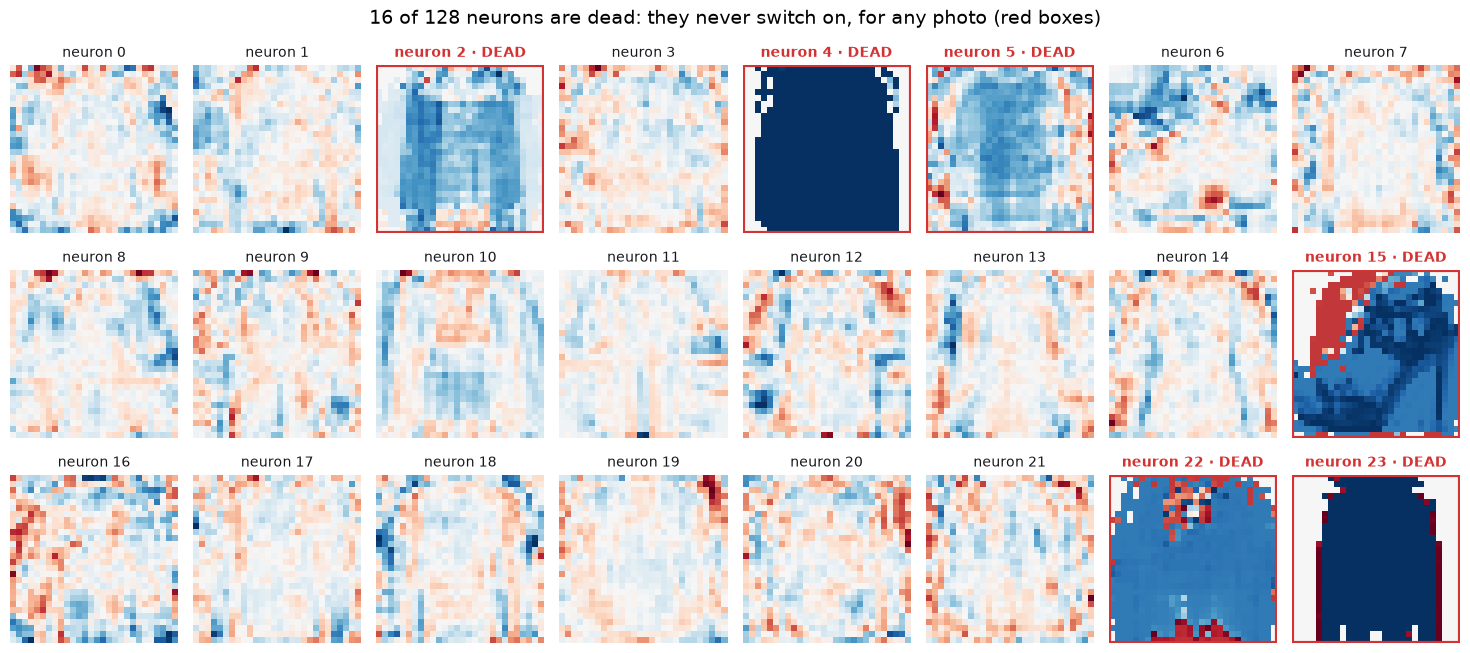

In [50]:
with torch.no_grad():
    fires = (model[1](X_train.flatten(1)) > 0).float().mean(dim = 0)
print("dead neurons: ", int((fires == 0).sum()), "of 128")
viz.show_neurons(learned, fires = fires)

## The scrambled model's secret

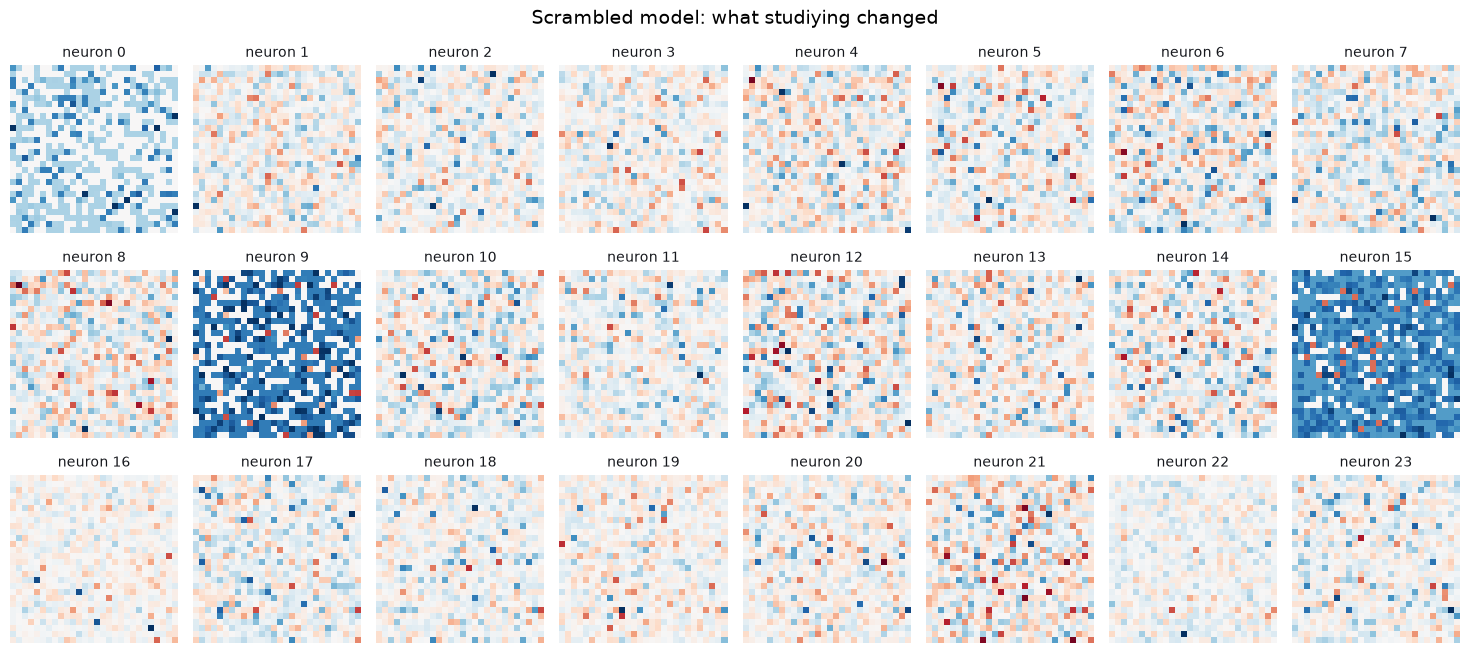

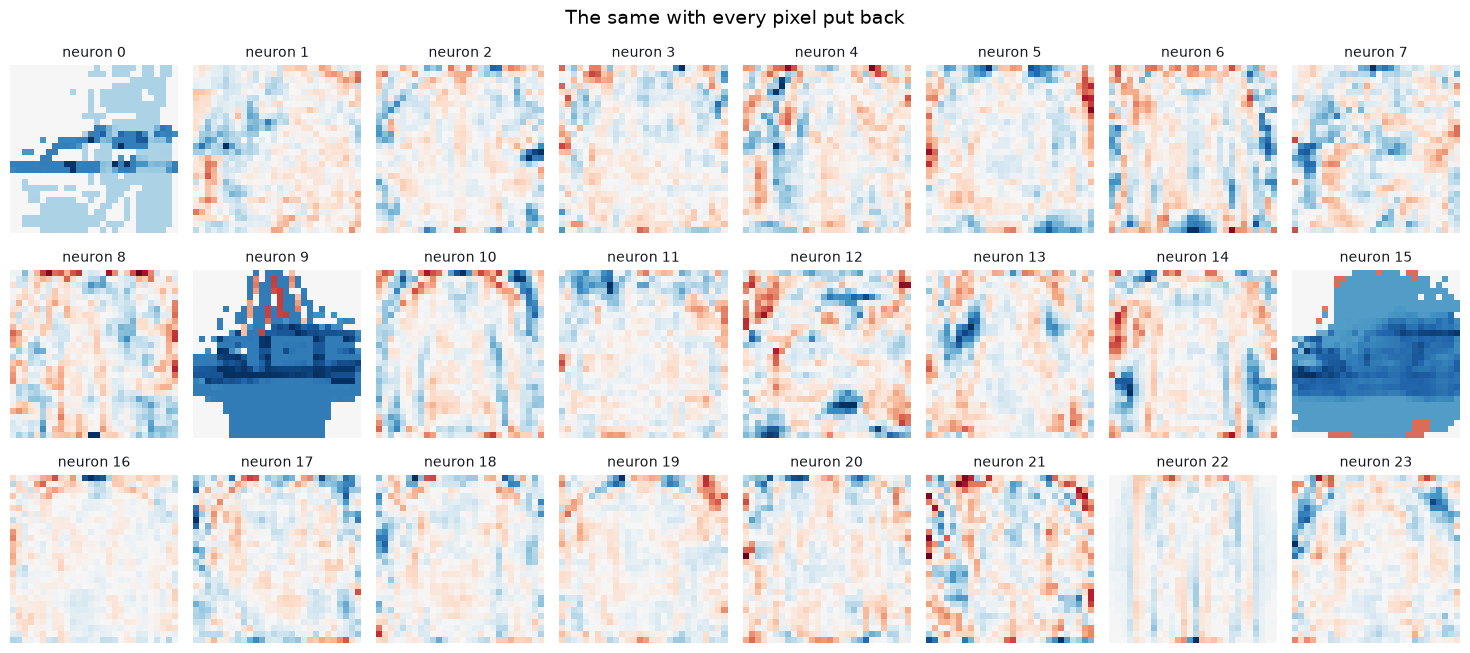

In [51]:
with torch.no_grad():
    learned_s = model_s[1].weight - start[1].weight
back = torch.zeros_like(learned_s)
back[:, order] = learned_s       # every weight back to it's pixel
viz.show_neurons(learned_s, title = "Scrambled model: what studiying changed")
viz.show_neurons(back, title = "The same with every pixel put back")

## Sliding the photos

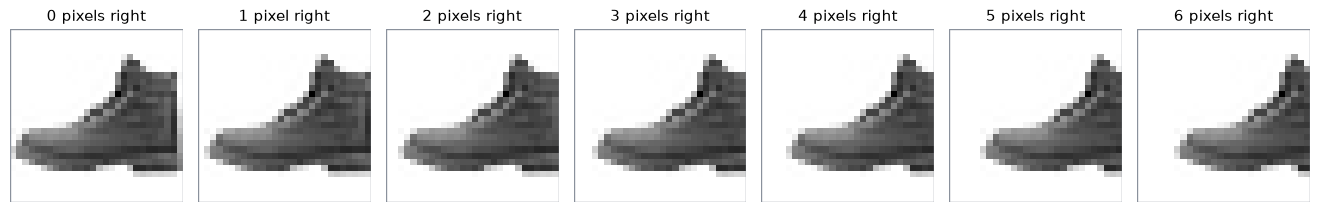

In [52]:
def shift(X, k):                        # Slide each photo k pixels right
    moved = torch.roll(X, shifts=k, dims = 2)
    moved[:, :, :k] = 0
    return moved

viz.show_slides(X_val[0], shift)

0 pixels right | mock test:  0.89
1 pixels right | mock test:  0.83
2 pixels right | mock test:  0.573
3 pixels right | mock test:  0.299
4 pixels right | mock test:  0.235
5 pixels right | mock test:  0.249
6 pixels right | mock test:  0.207


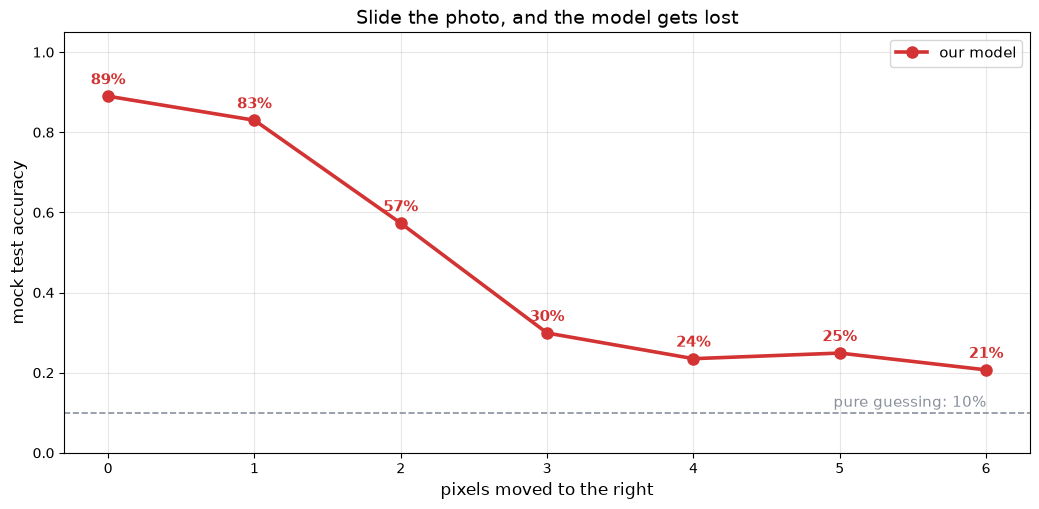

In [55]:
plain = []
for k in range(7):
    plain.append(accuracy(model, shift(X_val, k), y_val))
    print(k, "pixels right | mock test: ", plain[-1])
viz.show_shift_curve(plain)

In [56]:
def train_one_epoch_shifted(model, loader, loss_fn, optimizer):
    for xb, yb in loader:
        k = torch.randint(0, 4, (1,)).item()         # 0 to 3 pixels at random
        prediction = model(shift(xb, k))
        loss = loss_fn(prediction, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

[0.871, 0.88, 0.883, 0.871, 0.782, 0.519, 0.347]


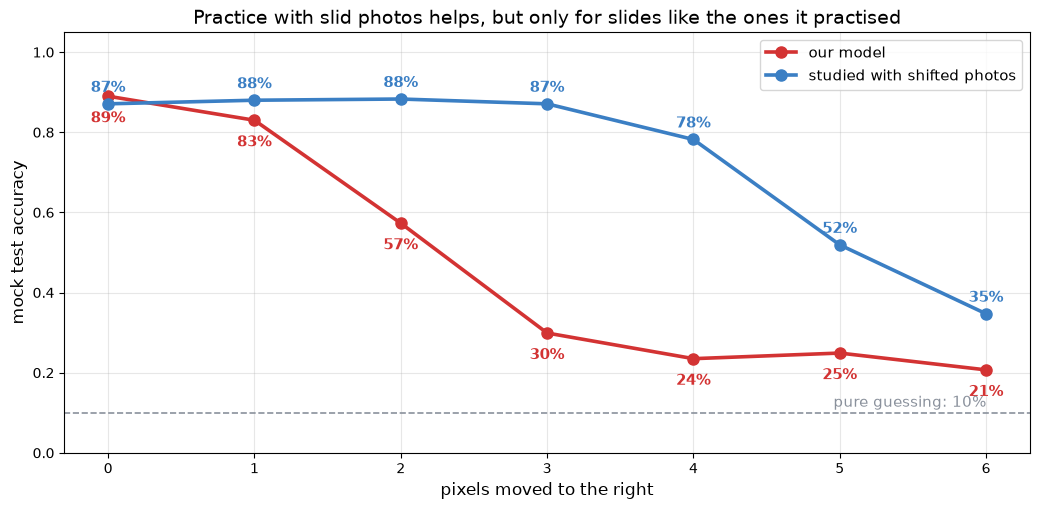

In [57]:
torch.manual_seed(42)
model_aug = new_shop_model()
optimizer = torch.optim.Adam(model_aug.parameters(), lr = 0.001)
loader = DataLoader(TensorDataset(X_train, y_train),
                    batch_size = 64, shuffle = True)
for epoch in range(1, best_epoch + 1):
    train_one_epoch_shifted(model_aug, loader, loss_fn, optimizer)
shifted = [accuracy(model_aug, shift(X_val, k), y_val) for k in range(7)]
print(shifted)
viz.show_shift_curve(plain, shifted)